In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import tifffile as tiff
import numpy as np

root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))


from utils.display_videos import display_videos
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.motion_correct_preprocessing import save_data_as_tif

from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_correlation import diagnose_resonant_scan, frame_difference_noise, spatial_noise_correlation
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_joint_resonant_covariance,
)

fig_path = root_dir.parent / "figures" / "resonancescanningfixes"


In [2]:
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]

In [ ]:
movie_m845ad = tiff.imread(file_path).astype("float32")

In [11]:
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
movie_m493 = tiff.imread(file_path).astype("float32")

(9162, 512, 512)

In [15]:
display_videos([movie_m845ad], display_mode="common", percentiles=[20, 99.9])

dims=(8989, 512, 512)
dims=(8989, 512, 512)


In [ ]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection.motion_correction.LK_alignment import (
    xy_align,
)

res = xy_align(movie_m845ad[:1000, ...], max_shift=15)

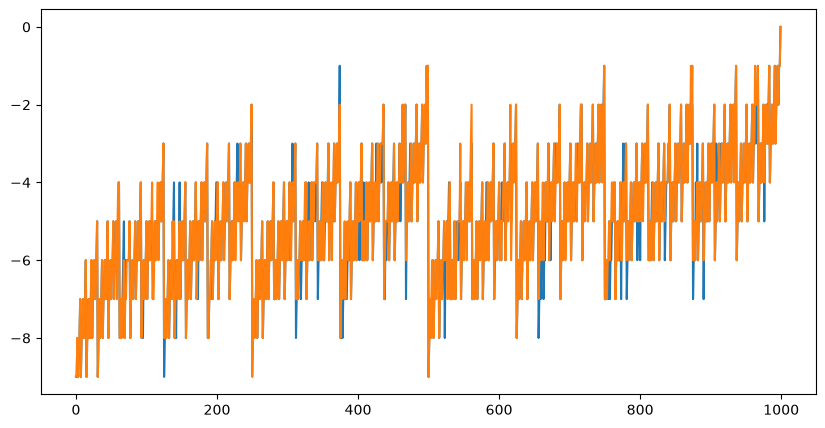

In [ ]:
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(10, 5))
plt.plot(res.T[:, 0])
plt.plot(res.T[:, 1])
plt.show()

# res.T

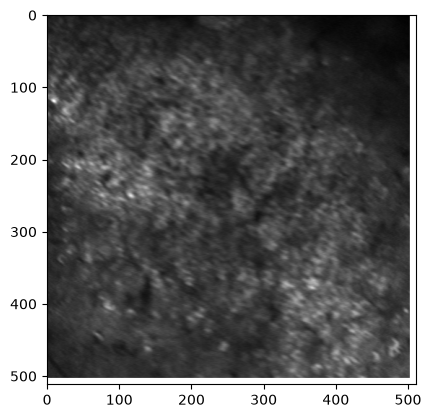

In [ ]:
plt.imshow(res.I, cmap="gray")

# res.I